In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(
    r"C:\Users\Public\Documents\NĂM 3\NLP\Đồ án\SemEval2027_Task8"
)
DATA_DIR = ROOT.parent / "StereoQueerEval_SemEval-2027" / "StereoQueerEval_training"
SEED = 42

df = pd.read_csv(
    DATA_DIR / "StereoQueerEval_EN_training.tsv",
    sep="\t",
    dtype=str,
    keep_default_na=False,
    encoding="utf-8",
)

folds = pd.read_csv(ROOT / "data/splits/folds_en.csv")

assert set(df["StereoQueerEval_id"]) == set(folds["StereoQueerEval_id"])

df = df.merge(
    folds[["StereoQueerEval_id", "video_id", "fold"]],
    on="StereoQueerEval_id",
    how="left",
    validate="one_to_one",
)

assert len(df) == 2989
assert df["fold"].notna().all()
assert set(df["fold"]) == set(range(5))
assert df.groupby("video_id")["fold"].nunique().eq(1).all()

display(df.groupby("fold").size())

fold
0    599
1    599
2    597
3    597
4    597
dtype: int64

In [3]:
TASKS = {
    "A": ("stereotype", ["no", "yes"]),
    "B": ("hate_speech", ["no", "yes_implicit", "yes_explicit"]),
}

INPUTS = {
    "comment": df["yt_comment"].to_numpy(),
    "comment_title": (
        df["yt_comment"] + "\n" + df["yt_title"]
    ).to_numpy(),
}

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline, FeatureUnion

def make_model(name):
    if name == "random":
        return DummyClassifier(strategy="uniform", random_state=SEED)

    if name == "majority":
        return DummyClassifier(strategy="most_frequent")

    if name != "tfidf_lr":
        raise ValueError(f"Model không hợp lệ: {name}")

    return Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(
                analyzer="word",
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True,
            )),
            ("char", TfidfVectorizer(
                analyzer="char",
                ngram_range=(2, 5),
                min_df=2,
                sublinear_tf=True,
            )),
        ])),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            C=1.0,
            max_iter=2000,
            random_state=SEED,
        )),
    ])

In [5]:
from sklearn.metrics import f1_score

def run_cv(model_name, texts, target_col, labels):
    y = df[target_col].to_numpy()
    fold_ids = df["fold"].to_numpy()

    oof_pred = np.empty(len(df), dtype=object)
    oof_proba = np.full((len(df), len(labels)), np.nan)
    fold_rows = []

    # DummyClassifier không cần đọc văn bản.
    X = (
        np.zeros((len(df), 1))
        if model_name in {"random", "majority"}
        else texts
    )

    for k in range(5):
        train = fold_ids != k
        valid = fold_ids == k

        model = make_model(model_name)
        model.fit(X[train], y[train])

        pred = model.predict(X[valid])
        proba = model.predict_proba(X[valid])

        oof_pred[valid] = pred

        # Thứ tự cột xác suất phải khớp tên nhãn.
        model_labels = list(model.classes_)
        for j, label in enumerate(labels):
            oof_proba[valid, j] = proba[:, model_labels.index(label)]

        class_f1 = f1_score(
            y[valid], pred,
            labels=labels, average=None, zero_division=0,
        )
        fold_rows.append({
            "fold": k,
            "macro_f1": class_f1.mean(),
            **{
                f"f1_{label}": score
                for label, score in zip(labels, class_f1)
            },
        })

    assert np.isfinite(oof_proba).all()
    assert np.allclose(oof_proba.sum(axis=1), 1)

    oof = df[["StereoQueerEval_id", "video_id", "fold"]].copy()
    oof["y_true"] = y
    oof["y_pred"] = oof_pred

    for j, label in enumerate(labels):
        oof[f"p_{label}"] = oof_proba[:, j]

    return pd.DataFrame(fold_rows), oof

In [6]:
scores, oof = run_cv(
    "tfidf_lr",
    INPUTS["comment"],
    *TASKS["B"],
)

display(scores)
print(
    f"Macro-F1: {scores['macro_f1'].mean():.4f}"
    f" ± {scores['macro_f1'].std(ddof=0):.4f}"
)

,fold,macro_f1,f1_no,f1_yes_implicit,f1_yes_explicit
0,0,0.524467,0.689775,0.373239,0.510386
1,1,0.529759,0.678201,0.401274,0.509804
2,2,0.536270,0.693805,0.424437,0.490566
3,3,0.535258,0.686411,0.397351,0.522013
4,4,0.498516,0.642735,0.332103,0.520710


Macro-F1: 0.5249 ± 0.0138


In [7]:
OOF_DIR = ROOT / "outputs/oof"
OOF_DIR.mkdir(parents=True, exist_ok=True)

oof.to_csv(
    OOF_DIR / "tfidf_lr_comment_B.csv",
    index=False,
    encoding="utf-8",
)

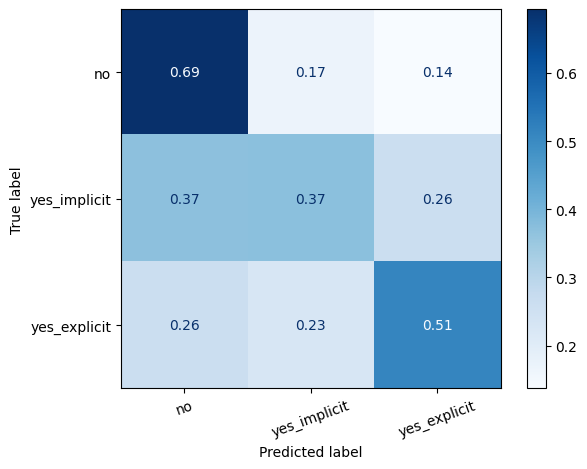

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    oof["y_true"],
    oof["y_pred"],
    labels=TASKS["B"][1],
    normalize="true",
    values_format=".2f",
    cmap="Blues",
)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [9]:
# Tính lại bảng điểm của cấu hình comment từ OOF đã lưu.
# Không cần train lại cấu hình cũ.
old_oof = pd.read_csv(OOF_DIR / "tfidf_lr_comment_B.csv")
labels = TASKS["B"][1]

old_rows = []
for fold, group in old_oof.groupby("fold"):
    per_class = f1_score(
        group["y_true"], group["y_pred"],
        labels=labels, average=None, zero_division=0,
    )
    old_rows.append({
        "macro_f1": per_class.mean(),
        **{f"f1_{label}": value
           for label, value in zip(labels, per_class)},
    })

scores_comment = pd.DataFrame(old_rows)

# Thí nghiệm mới: comment + title.
scores_title, oof_title = run_cv(
    "tfidf_lr",
    INPUTS["comment_title"],
    *TASKS["B"],
)

oof_title.to_csv(
    OOF_DIR / "tfidf_lr_comment_title_B.csv",
    index=False,
    encoding="utf-8",
)

comparison = pd.DataFrame({
    "comment": scores_comment.mean(),
    "comment_title": scores_title.drop(columns="fold").mean(),
})
comparison["change"] = (
    comparison["comment_title"] - comparison["comment"]
)

display(comparison.round(4))
print(
    f"Comment + title: {scores_title['macro_f1'].mean():.4f}"
    f" ± {scores_title['macro_f1'].std(ddof=0):.4f}"
)

,comment,comment_title,change
macro_f1,0.5249,0.4833,-0.0415
f1_no,0.6782,0.6705,-0.0077
f1_yes_implicit,0.3857,0.3113,-0.0744
f1_yes_explicit,0.5107,0.4682,-0.0425


Comment + title: 0.4833 ± 0.0216
